# CrisisMMD individual pipeline: dedup splits, baselines, early and late fusion

Works on the group's cached pooled features (EfficientNet-B0 + BERT) from the group's zip, so it needs no image download and runs on CPU in minutes.
It does not include cross-attention (that needs token-level features).


## 1. Settings

In [ ]:
import os, glob, time, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import binomtest
warnings.filterwarnings("ignore")

BASE = "/content"
ZIP_PATH = f"{BASE}/crisismmd_group_share.zip"
SHARE = f"{BASE}/crisismmd_group_share"
RESULTS = f"{BASE}/results"
PHASH_MAX_DIST = 6
DEDUP_RULE = "move"                                 # "move": each duplicate group goes to one split | "drop": delete dev/test copies
PLACEHOLDER_IDS_FILE = None                         # text file with one image_id per line, once the group has the list
FINAL_RUN = True                                    # True = evaluate on test (do this ONCE, after everything is frozen)
ALLOW_HF_FULLSET = False                            # True = if no agreed-label data is available, debug on the full Hugging Face set (NOT reportable)
RUN_TUNING = False                                  # True = run the small MLP tuning grid (dev only, about 12 minutes)
RUN_GATED = True                                    # True = also train the gated-fusion model (needs PyTorch)
RUN_SEEDS = True                                    # True = repeat the neural models over 5 seeds (final run)
SEED = 0

Path(RESULTS).mkdir(exist_ok=True, parents=True)
def sh(cmd): subprocess.run(cmd, shell=True, check=True)

## 2. Load the agreed-label subset
The notebook reads the official agreed-label files (`task_humanitarian_text_img_agreed_lab_{train,dev,test}.tsv`)
if they are under `/content`. They keep only tweet–image pairs whose separately annotated text and image labels match, with minority classes merged into five (Ofli et al., 2020). The reported results use these files.
Check the printed sizes: 6,126 / 998 / 955.

Fallbacks, not used for the reported results: (1) rebuild the subset from the all-labels split files, or (2) with
`ALLOW_HF_FULLSET = True`, load the full Hugging Face set for debugging only. That set is not the agreed subset,
so its numbers must not be reported.

In [ ]:
if not Path(SHARE).exists():
    sh(f"unzip -q -o {ZIP_PATH} -d {BASE}")

def tsv_files(pattern): return glob.glob(f"{BASE}/**/{pattern}", recursive=True)
if Path(f"{BASE}/splits.zip").exists() and not tsv_files("*humanitarian*agreed_lab_train.tsv"):
    sh(f"unzip -q -o {BASE}/splits.zip -d {BASE}")
def read_tsv(p): return pd.read_csv(p, sep="\t", dtype=str, quoting=3)     # quoting=3: tweets contain quote characters
MERGE = {"injured_or_dead_people": "affected_individuals", "missing_or_found_people": "affected_individuals",
         "vehicle_damage": "infrastructure_and_utility_damage"}
FULLSET = False

def load_hf_fullset():
    from huggingface_hub import hf_hub_download
    frames = []
    for s in ["train", "dev", "test"]:
        p = hf_hub_download("QCRI/CrisisMMD", f"humanitarian/{s}.json", repo_type="dataset")
        with open(p, encoding="utf-8") as fh: first = fh.read(2000).lstrip()[:1]
        d = pd.read_json(p, dtype=False) if first == "[" else pd.read_json(p, lines=True, dtype=False)   # JSON array or JSON lines
        frames.append(d.assign(split_original=s))
    d = pd.concat(frames, ignore_index=True)
    for c in ["tweet_id", "image_id"]: d[c] = d[c].astype(str)
    lab = d.label.astype(str)
    if lab.str.fullmatch(r"\d+").all():
        raise ValueError(f"labels are numbers {sorted(lab.unique())[:10]}: tell me, the class names are needed")
    d["label"] = lab.str.replace(r"^\d+", "", regex=True).replace(MERGE)
    return d

if tsv_files("*humanitarian*agreed_lab_train.tsv"):
    agreed = pd.concat([read_tsv(tsv_files(f"*humanitarian*agreed_lab_{s}.tsv")[0]).assign(split_original=s)
                        for s in ["train", "dev", "test"]], ignore_index=True)
    print("using the official agreed-label files")
else:
    if not tsv_files("task_humanitarian_text_img_train.tsv"):
        try:
            sh(f"wget -q -c https://crisisnlp.qcri.org/data/crisismmd/crisismmd_datasplit_all.zip -O {BASE}/splits_all.zip")
            sh(f"mkdir -p {BASE}/splits_all && unzip -q -o {BASE}/splits_all.zip -d {BASE}/splits_all")
        except subprocess.CalledProcessError:
            print("CrisisNLP download is blocked (403).")
    if tsv_files("task_humanitarian_text_img_train.tsv"):
        allf = pd.concat([read_tsv(tsv_files(f"task_humanitarian_text_img_{s}.tsv")[0]).assign(split_original=s)
                          for s in ["train", "dev", "test"]], ignore_index=True)
        agreed = allf[allf.label_text_image == "Positive"].copy()
        agreed["label"] = agreed.label.replace(MERGE)
        agreed = agreed.reset_index(drop=True)
        print("rebuilt the agreed subset from the all-labels files (Positive rows, minority classes merged)")
    elif ALLOW_HF_FULLSET:
        agreed = load_hf_fullset()
        FULLSET = True
        RESULTS = f"{BASE}/results_FULLSET_DEBUG"; Path(RESULTS).mkdir(exist_ok=True, parents=True)
        print("*" * 78)
        print("DEBUG MODE: this is the FULL Hugging Face set, NOT the agreed-label subset.")
        print("Use it only to test code. Do not report any of these numbers.")
        print("*" * 78)
    else:
        raise RuntimeError("No agreed-label data found. Put the agreed-label files (or Group's file) under /content, "
                           "or set ALLOW_HF_FULLSET = True to debug the code on the full Hugging Face set.")

print("columns:", agreed.columns.tolist())
sizes0 = agreed.split_original.value_counts().to_dict()
print("original sizes:", sizes0, "(proposal: 6126 / 998 / 955)")
if sizes0 != {"train": 6126, "dev": 998, "test": 955}:
    print("WARNING: sizes differ from the proposal, tell group before going further")
print("classes:", sorted(agreed.label.unique()))

using the official agreed-label files
columns: ['event_name', 'tweet_id', 'image_id', 'tweet_text', 'image', 'label', 'label_text', 'label_image', 'label_text_image', 'split_original']
original sizes: {'train': 6126, 'dev': 998, 'test': 955} (proposal: 6126 / 998 / 955)
classes: ['affected_individuals', 'infrastructure_and_utility_damage', 'not_humanitarian', 'other_relevant_information', 'rescue_volunteering_or_donation_effort']


## 3. Deduplicated splits from Group's pHash pairs
Images joined by a pair (distance <= `PHASH_MAX_DIST`) and images of the same tweet form one group. Each group is assigned to a single split
(train over dev over test). Limitation: the pairs file only lists cross-split pairs, so a near-copy inside a split cannot be seen here.

In [ ]:
pairs = pd.read_csv(f"{SHARE}/cache/near_duplicates_humanitarian.csv", dtype=str)
pairs["phash_distance"] = pairs.phash_distance.astype(int)
pairs = pairs[pairs.phash_distance <= PHASH_MAX_DIST]
row_of = {i: k for k, i in enumerate(agreed.image_id)}
edges = [(row_of[a], row_of[b]) for a, b in zip(pairs.image_id_A, pairs.image_id_B) if a in row_of and b in row_of]
print("pairs used:", len(edges), "of", len(pairs))
for _, idx in agreed.groupby("tweet_id").indices.items():       # images of one tweet stay together
    edges += [(idx[0], k) for k in idx[1:]]

def components(n, edges):
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for a, b in edges:
        ra, rb = find(a), find(b)
        if ra != rb: parent[rb] = ra
    return [find(i) for i in range(n)]

agreed["group"] = components(len(agreed), edges)
print("largest groups:", agreed.group.value_counts().head(5).tolist(), "(a very large group means chaining: lower the threshold)")

prio, inv = {"train": 0, "dev": 1, "test": 2}, {0: "train", 1: "dev", 2: "test"}
best = agreed.assign(p=agreed.split_original.map(prio)).groupby("group")["p"].transform("min")
agreed["split"] = best.map(inv)
if DEDUP_RULE == "drop":
    agreed = agreed[agreed.split == agreed.split_original].copy()
print("\nrows moved (original -> new):"); print(pd.crosstab(agreed.split_original, agreed.split))
print("\nfinal sizes:", agreed.split.value_counts().to_dict())
print("\nclass counts per split:"); print(pd.crosstab(agreed.label, agreed.split))

ids = set(Path(PLACEHOLDER_IDS_FILE).read_text().split()) if PLACEHOLDER_IDS_FILE else set()
agreed["has_image"] = ~agreed.image_id.isin(ids)
print("\nplaceholder images flagged:", int((~agreed.has_image).sum()))
agreed.drop(columns=[c for c in agreed.columns if c.startswith("tweet_text")]).to_csv(f"{RESULTS}/dedup_splits.csv", index=False)

pairs used: 287 of 287
largest groups: [55, 9, 9, 9, 8] (a very large group means chaining: lower the threshold)

rows moved (original -> new):
split           dev  test  train
split_original                  
dev             936     0     62
test              5   903     47
train             0     0   6126

final sizes: {'train': 6235, 'dev': 941, 'test': 903}

class counts per split:
split                                   dev  test  train
label                                                   
affected_individuals                      9     9     71
infrastructure_and_utility_damage        76    80    617
not_humanitarian                        498   477   3302
other_relevant_information              212   216   1325
rescue_volunteering_or_donation_effort  146   121    920

placeholder images flagged: 0


## 4. Load the cached features

In [ ]:
img = np.load(f"{SHARE}/cache/image_b0.npz", allow_pickle=True)    # only load files from the group folder
txt = np.load(f"{SHARE}/cache/text_bert.npz", allow_pickle=True)
img_map = {str(k): i for i, k in enumerate(img["image_id"])}
txt_map = {str(k): i for i, k in enumerate(txt["tweet_id"])}
IMG, TXT = img["feat"].astype(np.float32), txt["feat"].astype(np.float32)
print("image features:", IMG.shape, "| text features:", TXT.shape)
assert all(i in img_map for i in agreed.image_id) and all(t in txt_map for t in agreed.tweet_id), "id mismatch"

D = {}
for s in ["train", "dev", "test"]:
    df = agreed[agreed.split == s].reset_index(drop=True)
    D[s] = {"df": df, "y": df.label.values, "has_image": df.has_image.values,
            "image": IMG[[img_map[i] for i in df.image_id]], "text": TXT[[txt_map[t] for t in df.tweet_id]]}
mean_img = D["train"]["image"][D["train"]["has_image"]].mean(0)
for s in D:                                                          # missing (placeholder) images -> training mean
    D[s]["image"][~D[s]["has_image"]] = mean_img
    D[s]["early"] = np.hstack([D[s]["image"], D[s]["text"]])
classes = np.array(sorted(set(D["train"]["y"])))
print("classes:", classes.tolist())

image features: (18082, 1280) | text features: (16058, 768)
classes: ['affected_individuals', 'infrastructure_and_utility_damage', 'not_humanitarian', 'other_relevant_information', 'rescue_volunteering_or_donation_effort']


## 5. Models: logistic regression and a small MLP (class-weighted, tuned on dev)

In [ ]:
C_GRID = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

def fit_lr(name):
    t0 = time.time()
    sc = StandardScaler().fit(D["train"][name])
    xt, xd = sc.transform(D["train"][name]), sc.transform(D["dev"][name])
    best = None
    for c in C_GRID:
        m = LogisticRegression(C=c, max_iter=3000, class_weight="balanced").fit(xt, D["train"]["y"])
        f = f1_score(D["dev"]["y"], m.predict(xd), average="macro")
        if best is None or f > best[0]: best = (f, c, m)
    _, c, m = best
    return {"proba": lambda X, sc=sc, m=m: m.predict_proba(sc.transform(X)), "setting": f"C={c}", "C": c,
            "seconds": time.time() - t0, "params": int(m.coef_.size + m.intercept_.size), "history": None}

try:
    import torch, torch.nn as nn
    USE_MLP = True
except ImportError:
    USE_MLP = False

MLP_CFG = {"image": {"hidden": 64, "dropout": 0.7, "wd": 1e-3},      # one entry per model, edit after the tuning step
           "text":  {"hidden": 256, "dropout": 0.5, "wd": 1e-3},
           "early": {"hidden": 64, "dropout": 0.5, "wd": 1e-3}}

def fit_mlp(name, hidden=None, dropout=None, lr=1e-3, wd=None, epochs=80, patience=10, bs=128):
    cfg = MLP_CFG[name]
    hidden = hidden or cfg["hidden"]; dropout = dropout if dropout is not None else cfg["dropout"]; wd = wd if wd is not None else cfg["wd"]
    t0 = time.time()
    torch.manual_seed(SEED); np.random.seed(SEED)
    cidx = {c: i for i, c in enumerate(classes)}
    ytr = np.array([cidx[c] for c in D["train"]["y"]]); ydev = np.array([cidx[c] for c in D["dev"]["y"]])
    sc = StandardScaler().fit(D["train"][name])
    xtr = torch.tensor(sc.transform(D["train"][name]), dtype=torch.float32)
    xdev = torch.tensor(sc.transform(D["dev"][name]), dtype=torch.float32)
    ytr_t, ydev_t = torch.tensor(ytr), torch.tensor(ydev)
    counts = np.bincount(ytr, minlength=len(classes))
    w = torch.tensor(len(ytr) / (len(classes) * np.maximum(counts, 1)), dtype=torch.float32)
    net = nn.Sequential(nn.Linear(xtr.shape[1], hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, len(classes)))
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.CrossEntropyLoss(weight=w)
    best, best_state, bad, hist = -1.0, None, 0, []
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(xtr))
        tot = 0.0
        for i in range(0, len(xtr), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            loss = lossf(net(xtr[b]), ytr_t[b])
            loss.backward(); opt.step()
            tot += loss.item() * len(b)
        net.eval()
        with torch.no_grad():
            ptr = net(xtr).argmax(1).numpy()
            out_dev = net(xdev)
            pdev = out_dev.argmax(1).numpy()
            dev_loss = lossf(out_dev, ydev_t).item()
        f_dev, f_tr = f1_score(ydev, pdev, average="macro"), f1_score(ytr, ptr, average="macro")
        hist.append({"epoch": ep + 1, "train_loss": tot / len(xtr), "dev_loss": dev_loss, "train_mF1": f_tr, "dev_mF1": f_dev})
        if f_dev > best:
            best, bad = f_dev, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(best_state); net.eval()
    def proba(X, sc=sc, net=net):
        with torch.no_grad():
            return torch.softmax(net(torch.tensor(sc.transform(X), dtype=torch.float32)), 1).numpy()
    hist = pd.DataFrame(hist)
    return {"proba": proba, "setting": f"hidden={hidden}, dropout={dropout}, best epoch={int(hist.dev_mF1.idxmax()) + 1}",
            "seconds": time.time() - t0, "params": sum(p.numel() for p in net.parameters()), "history": hist}

print("MLP available:", USE_MLP)

MLP available: True


## 5b. Optional: small MLP tuning grid (dev only)
Trains the image, text and early-fusion MLPs for a few settings each (3 seeds each) and prints the mean dev macro-F1 per model, so the unimodal baselines get tuned as fairly as the fusion model. Dev has only about 940 rows, so differences
of 0.01 are noise: pick a sensible setting for each model, write it into `MLP_CFG` above, and rerun from the top. Set `RUN_TUNING = True` to use it.

In [ ]:
SPLITS_ALL = ["train", "dev", "test"]
if RUN_TUNING and USE_MLP:
    for tname in ["image", "text", "early"]:
        grid = []
        for h in [64, 256]:
            for dr in [0.5, 0.7]:
                for wd in [1e-4, 1e-3, 1e-2]:
                    f = []
                    for sd in range(3):
                        SEED = sd
                        r = fit_mlp(tname, hidden=h, dropout=dr, wd=wd)
                        f.append(f1_score(D["dev"]["y"], classes[r["proba"](D["dev"][tname]).argmax(1)], average="macro"))
                    grid.append({"hidden": h, "dropout": dr, "weight_decay": wd, "dev macroF1 mean": np.mean(f), "std": np.std(f)})
        g = pd.DataFrame(grid).sort_values("dev macroF1 mean", ascending=False)
        print(f"--- tuning grid for MLP-{tname} (3 seeds each) ---"); print(g.round(3).to_string(index=False))
        near = g[g["dev macroF1 mean"] >= g["dev macroF1 mean"].max() - 0.005].sort_values(["hidden", "dev macroF1 mean"], ascending=[True, False]).iloc[0]
        print(f"suggested (simplest within 0.005 of the best): hidden={int(near.hidden)}, dropout={near.dropout}, wd={near.weight_decay}\n")
    SEED = 0
    print("Copy the suggested values into MLP_CFG (one entry per model), set RUN_TUNING = False and rerun from the top.")

In [ ]:
SPLITS_ALL = ["train", "dev", "test"]
RES = {}      # (family, model) -> {"P": {split: probabilities}, "setting", "seconds", "params", "history"}

def run_family(family, fit):
    fitted = {name: fit(name) for name in ["image", "text", "early"]}
    for name, r in fitted.items():
        r["P"] = {s: r["proba"](D[s][name]) for s in SPLITS_ALL}
        RES[(family, name)] = r
    # late fusion: weighted mean of the unimodal probabilities; images that are missing fall back to text only
    Pi, Pt = fitted["image"]["P"], fitted["text"]["P"]
    def mix(w, s):
        p = w * Pi[s] + (1 - w) * Pt[s]
        p[~D[s]["has_image"]] = Pt[s][~D[s]["has_image"]]
        return p
    ws = np.linspace(0, 1, 11)
    w_best = max(ws, key=lambda w: f1_score(D["dev"]["y"], classes[mix(w, "dev").argmax(1)], average="macro"))
    RES[(family, "late")] = {"P": {s: mix(w_best, s) for s in SPLITS_ALL}, "setting": f"w_image={w_best:.1f}",
                             "seconds": fitted["image"]["seconds"] + fitted["text"]["seconds"],
                             "params": fitted["image"]["params"] + fitted["text"]["params"], "history": None}

run_family("LR", fit_lr)
if USE_MLP: run_family("MLP", fit_mlp)
print("trained:", [f"{a}-{b}" for a, b in RES])

trained: ['LR-image', 'LR-text', 'LR-early', 'LR-late', 'MLP-image', 'MLP-text', 'MLP-early', 'MLP-late']


## 5c. Third method: gated fusion (learns how much to trust each modality)
Each modality is projected to a hidden vector; a learned gate `g` (0 to 1) decides, per tweet, how much weight the image gets against the text:
`fused = g * image + (1 - g) * text`. If the image is missing the gate is forced to 0 (text only).

In [ ]:
def fit_gated(hidden=128, dropout=0.5, lr=1e-3, wd=1e-3, epochs=80, patience=10, bs=128):
    t0 = time.time()
    torch.manual_seed(SEED); np.random.seed(SEED)
    cidx = {c: i for i, c in enumerate(classes)}
    Y = {s: np.array([cidx[c] for c in D[s]["y"]]) for s in SPLITS_ALL}
    sci, sct = StandardScaler().fit(D["train"]["image"]), StandardScaler().fit(D["train"]["text"])
    T = {s: (torch.tensor(sci.transform(D[s]["image"]), dtype=torch.float32),
             torch.tensor(sct.transform(D[s]["text"]), dtype=torch.float32),
             torch.tensor(D[s]["has_image"].astype(np.float32))) for s in SPLITS_ALL}

    class Gated(nn.Module):
        def __init__(self, di, dt, h, k, p):
            super().__init__()
            self.fi, self.ft = nn.Linear(di, h), nn.Linear(dt, h)
            self.gate, self.drop, self.out = nn.Linear(2 * h, 1), nn.Dropout(p), nn.Linear(h, k)
        def forward(self, xi, xt, has):
            hi, ht = torch.tanh(self.fi(xi)), torch.tanh(self.ft(xt))
            g = torch.sigmoid(self.gate(torch.cat([hi, ht], 1))) * has.unsqueeze(1)   # missing image -> gate 0 -> text only
            return self.out(self.drop(g * hi + (1 - g) * ht)), g

    net = Gated(T["train"][0].shape[1], T["train"][1].shape[1], hidden, len(classes), dropout)
    counts = np.bincount(Y["train"], minlength=len(classes))
    w = torch.tensor(len(Y["train"]) / (len(classes) * np.maximum(counts, 1)), dtype=torch.float32)
    lossf = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    ytr_t, ydev_t = torch.tensor(Y["train"]), torch.tensor(Y["dev"])
    best, best_state, bad, hist = -1.0, None, 0, []
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(ytr_t)); tot = 0.0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            out, _ = net(T["train"][0][b], T["train"][1][b], T["train"][2][b])
            loss = lossf(out, ytr_t[b]); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        net.eval()
        with torch.no_grad():
            o_tr, _ = net(*T["train"]); o_dv, _ = net(*T["dev"])
            dev_loss = lossf(o_dv, ydev_t).item()
        f_tr = f1_score(Y["train"], o_tr.argmax(1).numpy(), average="macro")
        f_dv = f1_score(Y["dev"], o_dv.argmax(1).numpy(), average="macro")
        hist.append({"epoch": ep + 1, "train_loss": tot / len(perm), "dev_loss": dev_loss, "train_mF1": f_tr, "dev_mF1": f_dv})
        if f_dv > best:
            best, bad = f_dv, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(best_state); net.eval()
    P, G = {}, {}
    with torch.no_grad():
        for s in SPLITS_ALL:
            o, g = net(*T[s])
            P[s], G[s] = torch.softmax(o, 1).numpy(), g.numpy().ravel()
    hist = pd.DataFrame(hist)
    return {"P": P, "gate": G, "history": hist, "seconds": time.time() - t0, "params": sum(p.numel() for p in net.parameters()),
            "setting": f"hidden={hidden}, dropout={dropout}, wd={wd}, best epoch={int(hist.dev_mF1.idxmax()) + 1}"}

def register_gated(key=("GATED", "gated")):
    r = fit_gated()
    RES[key] = {"P": r["P"], "setting": r["setting"], "seconds": r["seconds"], "params": r["params"], "history": r["history"], "gate": r["gate"]}

if RUN_GATED and USE_MLP:
    register_gated()
    g = pd.Series(RES[("GATED", "gated")]["gate"]["dev"])
    print("gated fusion trained | mean image weight on dev, by true class (higher = relies more on the image):")
    print(g.groupby(D["dev"]["y"]).mean().round(2).to_string())

gated fusion trained | mean image weight on dev, by true class (higher = relies more on the image):
affected_individuals                      0.47
infrastructure_and_utility_damage         0.71
not_humanitarian                          0.43
other_relevant_information                0.72
rescue_volunteering_or_donation_effort    0.36


## 6. Evaluation (dev only unless `FINAL_RUN = True`)

In [ ]:
EVAL = "test" if FINAL_RUN else "dev"
if FULLSET: print("*** DEBUG ONLY: full set, not the agreed subset. Do not report these numbers. ***")
shown = ["train", "dev"] + (["test"] if FINAL_RUN else [])
print(f"Comparisons below use the {EVAL.upper()} split." + ("" if FINAL_RUN else " (test untouched)"))

def pred_of(key, s): return classes[RES[key]["P"][s].argmax(1)]

rows = []
for key, r in RES.items():
    row = {"family": key[0], "model": key[1], "setting": r["setting"], "fit_seconds": round(r["seconds"], 1), "params": r["params"]}
    for s in shown:
        p, y = pred_of(key, s), D[s]["y"]
        row[f"{s} acc"] = round(accuracy_score(y, p), 3)
        row[f"{s} macroF1"] = round(f1_score(y, p, average="macro"), 3)
        row[f"{s} weightedF1"] = round(f1_score(y, p, average="weighted"), 3)
    rows.append(row)
table = pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv(f"{RESULTS}/main_table.csv", index=False)

Comparisons below use the TEST split.
family model                                         setting  fit_seconds  params  train acc  train macroF1  train weightedF1  dev acc  dev macroF1  dev weightedF1  test acc  test macroF1  test weightedF1
    LR image                                         C=0.001         58.4    6405      0.824          0.791             0.826    0.744        0.632           0.750     0.776         0.701            0.780
    LR  text                                          C=0.01         35.8    3845      0.873          0.854             0.875    0.755        0.657           0.758     0.764         0.679            0.769
    LR early                                          C=0.01         76.6   10245      0.975          0.981             0.975    0.850        0.767           0.851     0.857         0.791            0.859
    LR  late                                     w_image=0.5         94.2   10250      0.917          0.915             0.917    0.832        

In [ ]:
def bootstrap_diff(y, pa, pb, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n, len(y)))
    d = [f1_score(y[i], pa[i], average="macro") - f1_score(y[i], pb[i], average="macro") for i in idx]
    return np.percentile(d, [2.5, 97.5])

def mcnemar_exact(y, pa, pb):
    a_ok, b_ok = pa == y, pb == y
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return b, c, (binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0)

y = D[EVAL]["y"]
singles = [k for k in RES if k[1] in ("image", "text")]
best_uni = max(singles, key=lambda k: f1_score(D["dev"]["y"], pred_of(k, "dev"), average="macro"))
print("strongest single-modality model (chosen on dev):", best_uni)
comp = []
for k in [k for k in RES if k[1] in ("early", "late", "gated")]:
    refs = [best_uni] + [r for r in [(k[0], "image"), (k[0], "text")] if r in RES and r != best_uni]
    for ref in refs:
        pa, pb = pred_of(k, EVAL), pred_of(ref, EVAL)
        diff = f1_score(y, pa, average="macro") - f1_score(y, pb, average="macro")
        lo, hi = bootstrap_diff(y, pa, pb)
        b, c, p = mcnemar_exact(y, pa, pb)
        comp.append({"fusion model": f"{k[0]}-{k[1]}", "compared with": f"{ref[0]}-{ref[1]}" + (" (strongest single)" if ref == best_uni else ""),
                     "macroF1 diff": round(diff, 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                     "fusion right/other wrong": b, "other right/fusion wrong": c, "McNemar p": f"{p:.1e}",
                     "meets bar (diff>=0.05, CI>0)": bool(diff >= 0.05 and lo > 0)})
comp = pd.DataFrame(comp)
print(comp.to_string(index=False))
comp.to_csv(f"{RESULTS}/comparisons.csv", index=False)

strongest single-modality model (chosen on dev): ('MLP', 'text')
fusion model               compared with  macroF1 diff          95% CI  fusion right/other wrong  other right/fusion wrong McNemar p  meets bar (diff>=0.05, CI>0)
    LR-early MLP-text (strongest single)         0.069  [0.001, 0.143]                       103                        40   1.4e-07                          True
    LR-early                    LR-image         0.090  [0.040, 0.139]                       122                        49   2.3e-08                          True
    LR-early                     LR-text         0.112  [0.056, 0.168]                       121                        37   1.3e-11                          True
     LR-late MLP-text (strongest single)         0.072  [0.026, 0.131]                        88                        29   4.3e-08                          True
     LR-late                    LR-image         0.093  [0.026, 0.155]                       115                        

In [ ]:
per = pd.DataFrame({f"{k[0]}-{k[1]}": f1_score(y, pred_of(k, EVAL), average=None, labels=classes) for k in RES},
                   index=classes).round(3)
print("per-class F1 on", EVAL); print(per.to_string())
per.to_csv(f"{RESULTS}/per_class_f1.csv")

if "event_name" in D[EVAL]["df"].columns:
    ev = D[EVAL]["df"].event_name.values
    per_ev = {}
    for k in RES:
        p = pred_of(k, EVAL)
        per_ev[f"{k[0]}-{k[1]}"] = {e: f1_score(y[ev == e], p[ev == e], average="macro") for e in sorted(set(ev))}
    per_ev = pd.DataFrame(per_ev).round(3)
    per_ev.insert(0, "n", [int((ev == e).sum()) for e in per_ev.index])
    print("\nper-event macro-F1 on", EVAL, "(small events are noisy)"); print(per_ev.to_string())
    per_ev.to_csv(f"{RESULTS}/per_event_macroF1.csv")

per-class F1 on test
                                        LR-image  LR-text  LR-early  LR-late  MLP-image  MLP-text  MLP-early  MLP-late  GATED-gated
affected_individuals                       0.467    0.429     0.538    0.609      0.414     0.556      0.519     0.778        0.412
infrastructure_and_utility_damage          0.772    0.685     0.901    0.849      0.767     0.727      0.892     0.880        0.871
not_humanitarian                           0.810    0.811     0.884    0.882      0.816     0.833      0.904     0.892        0.869
other_relevant_information                 0.798    0.745     0.842    0.850      0.800     0.750      0.863     0.834        0.831
rescue_volunteering_or_donation_effort     0.656    0.724     0.789    0.778      0.645     0.742      0.825     0.834        0.797

per-event macro-F1 on test (small events are noisy)
                        n  LR-image  LR-text  LR-early  LR-late  MLP-image  MLP-text  MLP-early  MLP-late  GATED-gated
california_wild

## 6b. Where does the model go wrong?
Rows are the true class, columns the predicted class (each row sums to 100%). Change `CM_MODEL` to look at another model.

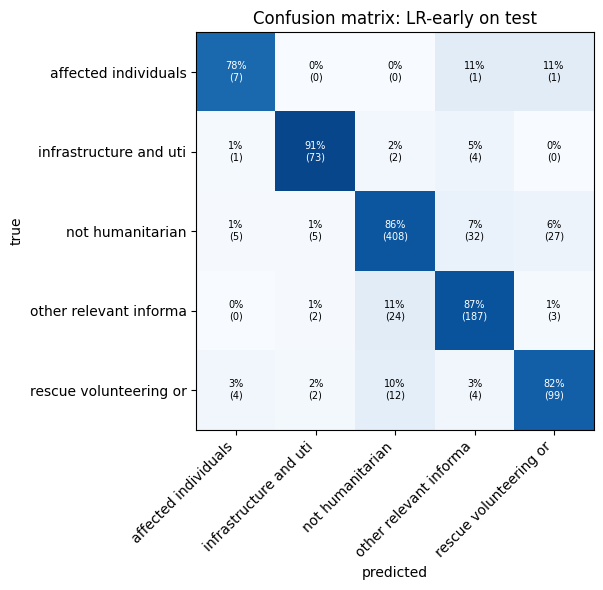

most common mistakes (count, true -> predicted):
    32  not_humanitarian -> other_relevant_information
    27  not_humanitarian -> rescue_volunteering_or_donation_effort
    24  other_relevant_information -> not_humanitarian
    12  rescue_volunteering_or_donation_effort -> not_humanitarian
     5  not_humanitarian -> infrastructure_and_utility_damage
     5  not_humanitarian -> affected_individuals


In [ ]:
from sklearn.metrics import confusion_matrix
CM_MODEL = ("LR", "early")
pred = pred_of(CM_MODEL, EVAL)
cm = confusion_matrix(y, pred, labels=classes)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
short = [c.replace("_", " ")[:22] for c in classes]
ax.set_xticks(range(len(classes))); ax.set_xticklabels(short, rotation=45, ha="right"); ax.set_yticks(range(len(classes))); ax.set_yticklabels(short)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "black")
ax.set(title=f"Confusion matrix: {CM_MODEL[0]}-{CM_MODEL[1]} on {EVAL}", xlabel="predicted", ylabel="true")
plt.tight_layout(); plt.savefig(f"{RESULTS}/confusion_matrix.png", dpi=150); plt.show()
off = [(cm[i, j], classes[i], classes[j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
print("most common mistakes (count, true -> predicted):")
for n, a, b in sorted(off, reverse=True)[:6]: print(f"  {n:4d}  {a} -> {b}")

## 6c. Unseen-event test
For each event: train on the other events (train and dev rows only, logistic regression with the settings chosen above), then test on the held-out event.
This asks whether the models cope with a new disaster. While `FINAL_RUN = False` the held-out rows come from train and dev only.
Macro-F1 is computed over the classes present in that event, so small events are noisy: look at weighted F1 and accuracy too.

In [ ]:
split_of = np.concatenate([[s] * len(D[s]["y"]) for s in SPLITS_ALL])
ev = np.concatenate([D[s]["df"].event_name.values for s in SPLITS_ALL])
Yall = np.concatenate([D[s]["y"] for s in SPLITS_ALL])
HAS = np.concatenate([D[s]["has_image"] for s in SPLITS_ALL])
XX = {k: np.vstack([D[s][k] for s in SPLITS_ALL]) for k in ["image", "text", "early"]}
w_late = float(RES[("LR", "late")]["setting"].split("=")[1])
held_splits = SPLITS_ALL if FINAL_RUN else ["train", "dev"]
loeo = []
for held in sorted(set(ev)):
    tr = (ev != held) & np.isin(split_of, ["train", "dev"])
    te = (ev == held) & np.isin(split_of, held_splits)
    if tr.sum() == 0 or te.sum() == 0: continue          # nothing to train on, or nothing to test on
    P = {}
    for k in ["image", "text", "early"]:
        sc = StandardScaler().fit(XX[k][tr])
        m = LogisticRegression(C=RES[("LR", k)]["C"], max_iter=3000, class_weight="balanced").fit(sc.transform(XX[k][tr]), Yall[tr])
        assert list(m.classes_) == list(classes)
        P[k] = m.predict_proba(sc.transform(XX[k][te]))
    pl = w_late * P["image"] + (1 - w_late) * P["text"]
    pl[~HAS[te]] = P["text"][~HAS[te]]
    P["late"] = pl
    for k, p in P.items():
        pr = classes[p.argmax(1)]
        loeo.append({"held-out event": held, "n": int(te.sum()), "model": k, "accuracy": accuracy_score(Yall[te], pr),
                     "macroF1": f1_score(Yall[te], pr, average="macro"), "weightedF1": f1_score(Yall[te], pr, average="weighted")})
if loeo:
    loeo = pd.DataFrame(loeo).round(3)
    print("weighted F1 on the held-out event (columns = model, n = rows tested):")
    print(loeo.pivot(index="held-out event", columns="model", values="weightedF1").assign(n=loeo.groupby("held-out event").n.first()).to_string())
    loeo.to_csv(f"{RESULTS}/unseen_event_results.csv", index=False)
else:
    print("skipped: needs at least two events")

weighted F1 on the held-out event (columns = model, n = rows tested):
model                 early  image   late   text     n
held-out event                                        
california_wildfires  0.740  0.682  0.735  0.606   511
hurricane_harvey      0.858  0.788  0.859  0.780  1954
hurricane_irma        0.847  0.761  0.840  0.739  1848
hurricane_maria       0.861  0.752  0.848  0.793  2228
iraq_iran_earthquake  0.728  0.627  0.686  0.579   227
mexico_earthquake     0.753  0.683  0.729  0.632   585
srilanka_floods       0.938  0.824  0.935  0.921   726


## 7. Overfitting: learning curves

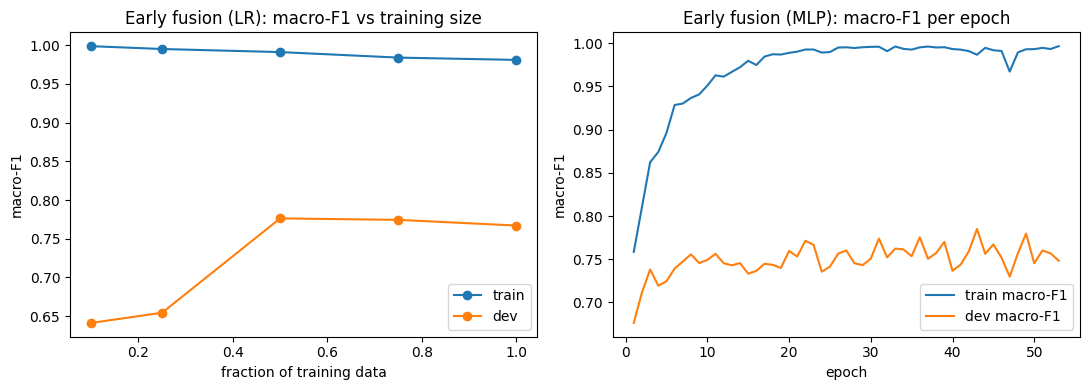

 train fraction  train macroF1  dev macroF1
           0.10          0.999        0.641
           0.25          0.995        0.654
           0.50          0.991        0.776
           0.75          0.984        0.774
           1.00          0.981        0.767


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rng = np.random.default_rng(SEED)
order = rng.permutation(len(D["train"]["y"]))
c_early = RES[("LR", "early")]["C"]
sc = StandardScaler().fit(D["train"]["early"])
curve = []
for f in [0.1, 0.25, 0.5, 0.75, 1.0]:
    sub = order[:int(f * len(order))]
    m = LogisticRegression(C=c_early, max_iter=3000, class_weight="balanced").fit(sc.transform(D["train"]["early"][sub]), D["train"]["y"][sub])
    curve.append((f, f1_score(D["train"]["y"][sub], m.predict(sc.transform(D["train"]["early"][sub])), average="macro"),
                  f1_score(D["dev"]["y"], m.predict(sc.transform(D["dev"]["early"])), average="macro")))
curve = pd.DataFrame(curve, columns=["train fraction", "train macroF1", "dev macroF1"])
ax[0].plot(curve["train fraction"], curve["train macroF1"], marker="o", label="train")
ax[0].plot(curve["train fraction"], curve["dev macroF1"], marker="o", label="dev")
ax[0].set(title="Early fusion (LR): macro-F1 vs training size", xlabel="fraction of training data", ylabel="macro-F1"); ax[0].legend()
h = RES.get(("MLP", "early"), {}).get("history")
if h is not None:
    ax[1].plot(h.epoch, h.train_mF1, label="train macro-F1"); ax[1].plot(h.epoch, h.dev_mF1, label="dev macro-F1")
    ax[1].set(title="Early fusion (MLP): macro-F1 per epoch", xlabel="epoch", ylabel="macro-F1"); ax[1].legend()
else:
    ax[1].axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS}/learning_curves.png", dpi=150); plt.show()
print(curve.round(3).to_string(index=False))

## 8. Final run only: repeat the neural models over 5 seeds
Neural models change a little with the random seed. Set `RUN_SEEDS = True` in the final run to report the mean and spread over the same split instead of one lucky run.

In [ ]:
if RUN_SEEDS and USE_MLP:
    y = D[EVAL]["y"]
    saved = dict(RES)
    for sd in range(5):
        SEED = sd
        run_family(f"MLP-s{sd}", fit_mlp)
        if RUN_GATED: register_gated((f"GATED-s{sd}", "gated"))
    sd_df = pd.DataFrame([{"family": k[0].split("-s")[0], "model": k[1], "macroF1": f1_score(y, pred_of(k, EVAL), average="macro"),
                           "accuracy": accuracy_score(y, pred_of(k, EVAL))} for k in RES if "-s" in k[0]])
    seed_table = sd_df.groupby(["family", "model"])[["macroF1", "accuracy"]].agg(["mean", "std"]).round(3)
    print(f"mean and std over 5 seeds on {EVAL}:"); print(seed_table.to_string())
    seed_table.to_csv(f"{RESULTS}/seed_summary.csv")
    RES.clear(); RES.update(saved); SEED = 0

mean and std over 5 seeds on test:
             macroF1        accuracy       
                mean    std     mean    std
family model                               
GATED  gated   0.770  0.014    0.849  0.006
MLP    early   0.806  0.013    0.871  0.005
       image   0.680  0.014    0.775  0.010
       late    0.815  0.027    0.862  0.018
       text    0.714  0.016    0.783  0.006


In [ ]:
!zip -r results_final.zip /content/results
from google.colab import files
files.download("results_final.zip")

  adding: content/results/ (stored 0%)
  adding: content/results/learning_curves.png (deflated 9%)
  adding: content/results/main_table.csv (deflated 55%)
  adding: content/results/per_class_f1.csv (deflated 43%)
  adding: content/results/confusion_matrix.png (deflated 11%)
  adding: content/results/comparisons.csv (deflated 56%)
  adding: content/results/unseen_event_results.csv (deflated 67%)
  adding: content/results/per_event_macroF1.csv (deflated 49%)
  adding: content/results/seed_summary.csv (deflated 38%)
  adding: content/results/dedup_splits.csv (deflated 90%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip freeze | grep -iE "^(numpy|pandas|scikit-learn|scipy|matplotlib|torch|torchvision|transformers|pillow|imagehash|huggingface-hub)=="
import sys; print(sys.version)

matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
pillow==11.3.0
scikit-learn==1.6.1
scipy==1.16.3
transformers==5.22.0
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:
import torch; print(torch.__version__)

2.11.0+cpu
